# 11 — Final Model Comparison

**Capstone:** Comparative Evaluation of Diffusion, GAN, and VAE Models for Synthetic Clinical Tabular Data Generation: Fidelity, Utility, and Privacy Risk Assessment

This notebook combines **saved** results from the earlier experiments. It does **not** retrain models, regenerate patient records, or require DGX/GPU access.

**Compared experiments:** TVAE 50, TVAE 300, CTGAN 300, TabDDPM 100. These are the runs actually completed; training epochs differ by model.

**Interpretation rule:** Favor transparent, metric-specific conclusions over a single composite rank. A privacy-proxy AUC close to 0.5 is *not* proof of privacy safety.

## 1. Setup (laptop or DGX)

Open this notebook from the project `notebooks/` folder. Select your local Python kernel with `pandas`, `numpy`, `matplotlib`, and `IPython`. The code automatically searches the current folder and its parent for `results/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
             if (p / 'results' / 'fidelity' / 'model_fidelity_summary.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Project not found. Open this notebook from the extracted project/notebooks folder.')
OUT = ROOT / 'results' / 'final_comparison'
OUT.mkdir(parents=True, exist_ok=True)
MODELS = ['TVAE 50', 'TVAE 300', 'CTGAN 300', 'TabDDPM 100']
COLORS = {'TVAE 50':'#8290b0', 'TVAE 300':'#596c9a', 'CTGAN 300':'#ba8c4c', 'TabDDPM 100':'#397f77'}
print('Project:', ROOT)
print('Figures and tables will be saved to:', OUT)

Project: c:\Users\Ayana santhosh khan\Documents\capstone-home\synthetic-clinical-data-generation
Figures and tables will be saved to: c:\Users\Ayana santhosh khan\Documents\capstone-home\synthetic-clinical-data-generation\results\final_comparison


## 2. Load completed evaluations

The numerical and categorical fidelity metrics were computed against the **real training split**. TSTR evaluates logistic regression trained on synthetic data against the **held-out real test split**. The privacy tests are observational indicators, not formal membership-inference guarantees.

In [2]:
required = {
    'fidelity': 'fidelity/model_fidelity_summary.csv',
    'utility': 'utility/tstr_logreg_results.csv',
    'exact': 'privacy/exact_full_row_matches.csv',
    'proximity': 'privacy/sample_nearest_neighbor_privacy.csv',
    'protocol': 'privacy/privacy_protocol.json',
}
for label, relative in required.items():
    path = ROOT / 'results' / relative
    if not path.is_file():
        raise FileNotFoundError(f'Missing {label}: {path}')
    print(f'Found {label}: {relative}')

fidelity = pd.read_csv(ROOT / 'results' / required['fidelity']).set_index('model').reindex(MODELS)
utility = pd.read_csv(ROOT / 'results' / required['utility']).set_index('train_source')
exact = pd.read_csv(ROOT / 'results' / required['exact']).set_index('model').reindex(MODELS)
proximity = pd.read_csv(ROOT / 'results' / required['proximity']).set_index('model').reindex(MODELS)
protocol = json.loads((ROOT / 'results' / required['protocol']).read_text(encoding='utf-8'))
if fidelity.isnull().all(axis=1).any() or proximity.isnull().all(axis=1).any():
    raise ValueError('A model is missing from the saved fidelity/privacy outputs')
if not all(name in utility.index for name in MODELS + ['TRTR (Real train)']):
    raise ValueError('Missing an expected TSTR model or real-data baseline')
print('Privacy sampling:', protocol['queries_per_group'], 'real train / test queries each;',
      protocol['synthetic_pool_per_model'], 'synthetic rows per model')
print('Real-trained predictive baseline AUROC:', round(float(utility.loc['TRTR (Real train)', 'auroc']), 4))

Found fidelity: fidelity/model_fidelity_summary.csv
Found utility: utility/tstr_logreg_results.csv
Found exact: privacy/exact_full_row_matches.csv
Found proximity: privacy/sample_nearest_neighbor_privacy.csv
Found protocol: privacy/privacy_protocol.json
Privacy sampling: 1000 real train / test queries each; 5000 synthetic rows per model
Real-trained predictive baseline AUROC: 0.6709


## 3. Unified comparison table

Metrics have distinct meanings; **do not average them into one score**. For fidelity, smaller gaps/distances are better; for coverage and TSTR, larger is generally better. For privacy, no straightforward 'larger is safer' rule applies.

In [3]:
comparison = pd.DataFrame(index=MODELS)
comparison.index.name = 'model'
comparison['readmission_rate_%'] = fidelity['positive_rate_pct']
comparison['readmission_abs_gap_pp_lower'] = fidelity['abs_rate_gap_pp']
comparison['numeric_KS_lower'] = fidelity['ks_statistic']
comparison['numeric_Wasserstein_normalized_lower'] = fidelity['normalized_wasserstein']
comparison['categorical_TVD_lower'] = fidelity['tvd']
comparison['real_category_coverage_%_higher'] = 100 * fidelity['real_category_coverage']
comparison['Spearman_gap_lower'] = fidelity['mean_abs_spearman_gap']
comparison['TSTR_AUROC_higher'] = utility.loc[MODELS, 'auroc']
comparison['TSTR_AUPRC_higher'] = utility.loc[MODELS, 'average_precision']
comparison['TSTR_F1_higher'] = utility.loc[MODELS, 'f1']
comparison['TSTR_recall_higher'] = utility.loc[MODELS, 'recall']
comparison['exact_training_row_matches'] = exact['exact_train_matches']
comparison['proximity_membership_AUC_proxy'] = proximity['proximity_membership_auc']

comparison.to_csv(OUT / 'all_model_comparison.csv')
print('Saved: results/final_comparison/all_model_comparison.csv')
display(comparison.round(4))

Saved: results/final_comparison/all_model_comparison.csv


,readmission_rate_%,readmission_abs_gap_pp_lower,numeric_KS_lower,numeric_Wasserstein_normalized_lower,categorical_TVD_lower,real_category_coverage_%_higher,Spearman_gap_lower,TSTR_AUROC_higher,TSTR_AUPRC_higher,TSTR_F1_higher,TSTR_recall_higher,exact_training_row_matches,proximity_membership_AUC_proxy
model,,,,,,,,,,,,,
TVAE 50,0.0000,11.3992,0.1805,0.2587,0.0902,53.6528,0.0969,0.5000,0.1135,0.0000,0.0000,0,0.4964
TVAE 300,0.0427,11.3565,0.1387,0.2092,0.0720,66.6678,0.0478,0.6007,0.1735,0.1223,0.0775,0,0.4996
CTGAN 300,4.1211,7.2781,0.1720,0.2964,0.0846,100.0000,0.1104,0.4966,0.1128,0.1738,0.4073,0,0.4907
TabDDPM 100,10.5659,0.8333,0.0378,0.0505,0.0143,91.9304,0.0188,0.6467,0.2095,0.2644,0.5499,0,0.4987


## 4. Fidelity: minority readmission, distributions and coverage

For clinical synthetic data, reproducing **the minority readmission class** matters. Category coverage by itself does not establish that category *frequencies* are well-matched.

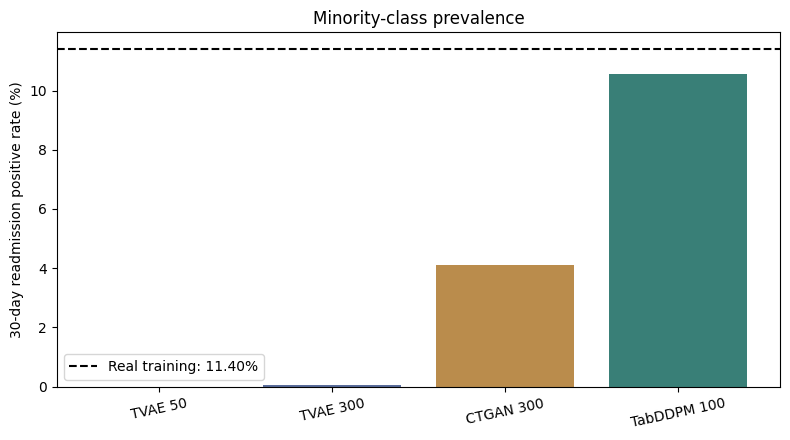

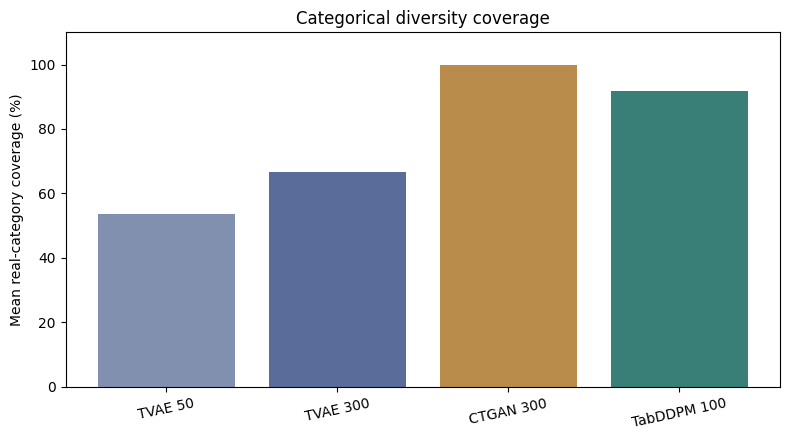

Smallest readmission gap: TabDDPM 100
Smallest numerical KS: TabDDPM 100
Smallest categorical TVD: TabDDPM 100
Highest category coverage: CTGAN 300


In [4]:
real_rate = float(pd.read_csv(ROOT / 'results/fidelity/readmission_prevalence.csv')
                  .set_index('dataset').loc['Real training', 'positive_rate_pct'])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(MODELS, fidelity['positive_rate_pct'].values, color=[COLORS[m] for m in MODELS])
ax.axhline(real_rate, color='black', linestyle='--', linewidth=1.5,
           label=f'Real training: {real_rate:.2f}%')
ax.set(ylabel='30-day readmission positive rate (%)', title='Minority-class prevalence')
ax.legend(); ax.tick_params(axis='x', rotation=12)
fig.tight_layout(); fig.savefig(OUT / 'readmission_comparison.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(MODELS, fidelity['real_category_coverage'] * 100, color=[COLORS[m] for m in MODELS])
ax.set(ylim=(0, 110), ylabel='Mean real-category coverage (%)', title='Categorical diversity coverage')
ax.tick_params(axis='x', rotation=12)
fig.tight_layout(); fig.savefig(OUT / 'category_coverage_comparison.png', dpi=180)
plt.show()

print('Smallest readmission gap:', fidelity['abs_rate_gap_pp'].idxmin())
print('Smallest numerical KS:', fidelity['ks_statistic'].idxmin())
print('Smallest categorical TVD:', fidelity['tvd'].idxmin())
print('Highest category coverage:', fidelity['real_category_coverage'].idxmax())

## 5. Predictive utility: synthetic-to-real transfer

**TRTR:** train on real, test on real (reference). **TSTR:** train on synthetic, test on held-out real. These are logistic-regression experiments, not a clinical deployment study. TVAE 50 had no positive training samples, so the saved evaluation used a **single-class fallback** rather than a fitted two-class classifier.

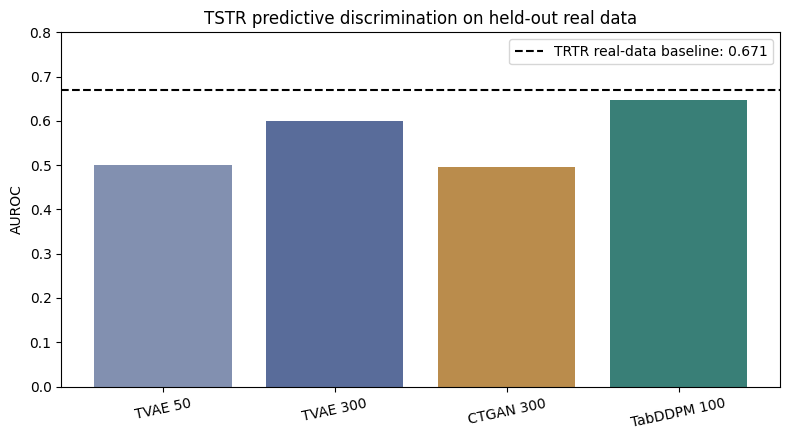

Real-data TRTR baseline AUROC / AUPRC: 0.6709 / 0.2264
Best synthetic TSTR AUROC: TabDDPM 100


In [5]:
trtr = utility.loc['TRTR (Real train)']
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(MODELS, utility.loc[MODELS, 'auroc'], color=[COLORS[m] for m in MODELS])
ax.axhline(float(trtr['auroc']), linestyle='--', color='black', label=f'TRTR real-data baseline: {trtr["auroc"]:.3f}')
ax.set(ylim=(0, 0.8), ylabel='AUROC', title='TSTR predictive discrimination on held-out real data')
ax.legend(); ax.tick_params(axis='x', rotation=12)
fig.tight_layout(); fig.savefig(OUT / 'tstr_auroc_comparison.png', dpi=180)
plt.show()

print('Real-data TRTR baseline AUROC / AUPRC:', round(float(trtr['auroc']),4), '/',round(float(trtr['average_precision']),4))
print('Best synthetic TSTR AUROC:', utility.loc[MODELS, 'auroc'].idxmax())

## 6. Privacy indicators and limitations

- Exact full-row matches compare all 45 fields; zero exact matches **does not** exclude near-copy or inference risks.
- The proximity membership proxy was sampled using **1,000 real-train records + 1,000 real-test records** and **5,000 synthetic rows per model**. AUC approximately 0.5 shows no detectable membership discrimination under this test; it is **not** a differential-privacy guarantee.
- Models may have privacy risks not captured by these indicators. Do not release record-level data publicly based on these scores.

,exact_training_matches,exact_test_matches,sampled_membership_proxy_AUC,median_train_to_synth_distance,median_test_to_synth_distance
model,,,,,
TVAE 50,0,0,0.4964,2.6262,2.6279
TVAE 300,0,0,0.4996,2.5765,2.5785
CTGAN 300,0,0,0.4907,2.8326,2.8217
TabDDPM 100,0,0,0.4987,2.6178,2.6298


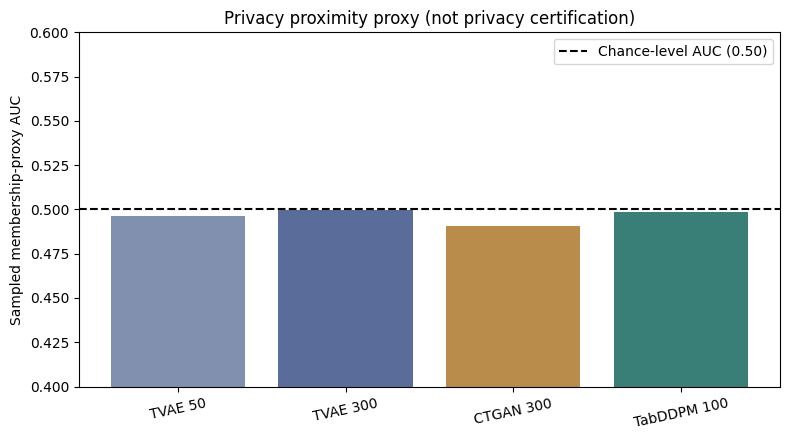

In [6]:
privacy_summary = pd.DataFrame({
    'exact_training_matches': exact['exact_train_matches'],
    'exact_test_matches': exact['exact_test_matches'],
    'sampled_membership_proxy_AUC': proximity['proximity_membership_auc'],
    'median_train_to_synth_distance': proximity['median_train_to_synth'],
    'median_test_to_synth_distance': proximity['median_test_to_synth'],
})
display(privacy_summary.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(MODELS, privacy_summary['sampled_membership_proxy_AUC'], color=[COLORS[m] for m in MODELS])
ax.axhline(0.5, linestyle='--', color='black', label='Chance-level AUC (0.50)')
ax.set(ylim=(0.40, 0.60), ylabel='Sampled membership-proxy AUC', title='Privacy proximity proxy (not privacy certification)')
ax.legend(); ax.tick_params(axis='x', rotation=12)
fig.tight_layout(); fig.savefig(OUT / 'privacy_proxy_comparison.png', dpi=180)
plt.show()

## 7. Evidence-based conclusion and report-ready summary

This section writes a plain Markdown summary alongside the numerical tables and figures. Please retain all limitations in the final report, including model-specific training budgets and the fact that the diffusion model was a **TabDDPM-inspired joint Gaussian–multinomial implementation**, not a verified exact replication of the official TabDDPM repository.

In [7]:
lead = 'TabDDPM 100'
ct = 'CTGAN 300'
report = f"""# Final comparison: saved experimental evidence

**Study setup.** Three generative families were tested on the same patient-disjoint UCI Diabetes training split (79,567 records) with a held-out real test split (19,773 records). Four saved experiments are included: TVAE 50, TVAE 300, CTGAN 300 and TabDDPM-inspired joint diffusion 100. Epoch counts and model families differ; results should not be interpreted as a controlled equal-compute benchmark.

**Statistical fidelity.** {lead} reproduced the positive 30-day readmission rate most closely: {fidelity.loc[lead,'positive_rate_pct']:.3f}% versus {real_rate:.3f}% in the real training data (absolute difference {fidelity.loc[lead,'abs_rate_gap_pp']:.3f} percentage points). It also had the lowest mean numerical KS ({fidelity.loc[lead,'ks_statistic']:.4f}), categorical TVD ({fidelity.loc[lead,'tvd']:.4f}), and Spearman correlation gap ({fidelity.loc[lead,'mean_abs_spearman_gap']:.4f}). {ct} had the largest average real-category coverage ({100*fidelity.loc[ct,'real_category_coverage']:.2f}%), compared with {100*fidelity.loc[lead,'real_category_coverage']:.2f}% for {lead}.

**Predictive utility.** On the same held-out real patients, TSTR logistic regression trained on {lead} achieved AUROC {utility.loc[lead,'auroc']:.4f}, AUPRC {utility.loc[lead,'average_precision']:.4f}, F1 {utility.loc[lead,'f1']:.4f}, and recall {utility.loc[lead,'recall']:.4f}. The real-data TRTR baseline achieved AUROC {trtr['auroc']:.4f} and AUPRC {trtr['average_precision']:.4f}. TVAE 50 generated zero positive cases; its reported TSTR score is the single-class fallback, not a fitted logistic regression model.

**Privacy indicators.** No synthetic model had an exact full-row match to the observed real training or held-out test records. Sampled proximity membership-proxy AUCs ranged from {proximity['proximity_membership_auc'].min():.4f} to {proximity['proximity_membership_auc'].max():.4f} using {protocol['queries_per_group']} real records from each group and {protocol['synthetic_pool_per_model']} sampled synthetic records per model. These heuristic results do **not** guarantee anonymity, differential privacy, or safe release.

**Conclusion.** In the measured fidelity and TSTR utility dimensions, {lead} was the strongest of the tested generators. {ct} preserved categorical coverage most completely. Privacy evaluation found no signal of exact memorization or strong proximity-based membership discrimination within the sampled test, but more rigorous auditing would be needed before any data-sharing decision.

**Limitations.** Different epoch budgets across models; single dataset and split; one downstream classifier; threshold-dependent F1/recall; sample-based privacy proxy; possible clinical plausibility issues beyond marginal/statistical tests; synthetic tabular diffusion is TabDDPM-inspired and should be described precisely.
"""
(OUT / 'final_comparison_findings.md').write_text(report, encoding='utf-8')
print('Saved: results/final_comparison/final_comparison_findings.md')
display(Markdown(report))

Saved: results/final_comparison/final_comparison_findings.md


# Final comparison: saved experimental evidence

**Study setup.** Three generative families were tested on the same patient-disjoint UCI Diabetes training split (79,567 records) with a held-out real test split (19,773 records). Four saved experiments are included: TVAE 50, TVAE 300, CTGAN 300 and TabDDPM-inspired joint diffusion 100. Epoch counts and model families differ; results should not be interpreted as a controlled equal-compute benchmark.

**Statistical fidelity.** TabDDPM 100 reproduced the positive 30-day readmission rate most closely: 10.566% versus 11.399% in the real training data (absolute difference 0.833 percentage points). It also had the lowest mean numerical KS (0.0378), categorical TVD (0.0143), and Spearman correlation gap (0.0188). CTGAN 300 had the largest average real-category coverage (100.00%), compared with 91.93% for TabDDPM 100.

**Predictive utility.** On the same held-out real patients, TSTR logistic regression trained on TabDDPM 100 achieved AUROC 0.6467, AUPRC 0.2095, F1 0.2644, and recall 0.5499. The real-data TRTR baseline achieved AUROC 0.6709 and AUPRC 0.2264. TVAE 50 generated zero positive cases; its reported TSTR score is the single-class fallback, not a fitted logistic regression model.

**Privacy indicators.** No synthetic model had an exact full-row match to the observed real training or held-out test records. Sampled proximity membership-proxy AUCs ranged from 0.4907 to 0.4996 using 1000 real records from each group and 5000 sampled synthetic records per model. These heuristic results do **not** guarantee anonymity, differential privacy, or safe release.

**Conclusion.** In the measured fidelity and TSTR utility dimensions, TabDDPM 100 was the strongest of the tested generators. CTGAN 300 preserved categorical coverage most completely. Privacy evaluation found no signal of exact memorization or strong proximity-based membership discrimination within the sampled test, but more rigorous auditing would be needed before any data-sharing decision.

**Limitations.** Different epoch budgets across models; single dataset and split; one downstream classifier; threshold-dependent F1/recall; sample-based privacy proxy; possible clinical plausibility issues beyond marginal/statistical tests; synthetic tabular diffusion is TabDDPM-inspired and should be described precisely.


## 8. Outputs

The code saves `results/final_comparison/all_model_comparison.csv`, `final_comparison_findings.md`, and four PNG comparison charts. This section requires no DGX connection. Preserve the original `results/fidelity`, `results/utility`, and `results/privacy` directories as immutable evidence from the completed experiments.